# Thermo-optic phase shifter in 3D

A thermo-optic phase shifter in 3D is a TiN heater over a silicon waveguide spiral.

**Question.** A silicon waveguide is folded into a racetrack double spiral, and a
thin titanium nitride (TiN) strip 2.2 µm above it carries a current. Silicon's
index rises with temperature, so the light picks up an extra phase delay along
the warm parts of the guide. What heater power gives a phase shift of $\pi$ over the
whole spiral? How is that phase shared between the passes under the heater and
those beside it, which pick it up as thermal crosstalk? How fast does the phase
follow a step in the current?

The device is too long to model as a cross-section: the heater crosses the
spiral's bends, heat spreads along and across the passes, and the guide's
1242 µm route turns 16 times. Here the whole chip is solved in 3D: the
current in the heater, the steady temperature, the phase integrated along the
route through a 2D mode of the guide, and the temperature over time after a
step.

**What the run found.** The heater's resistance is 99.16 Ω. Each watt of
heater power delays the light by 702.3 rad over the route, so a $\pi$ shift
takes **$P_\pi = 4.473$ mW**. The six passes under the heater carry
32 % of the phase; the outermost passes, about 10 µm beyond
the heater's edge, still pick up 8.8 % of the centre
pass's phase per pass. After the current is switched on, the phase reaches 63 % of
its final value in 17 µs and goes from 10 % to 90 % in
34.3 µs. The mesh error in $P_\pi$ is about
0.07 % ("Check your results").

This page shows a saved run: the solves need gmsh to build the mesh and a few GiB
of memory, so the page reads their results and solves nothing ("How this was
run").

In [1]:
import hashlib
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Polygon

ROOT, DATA = Path("../.."), Path("data")
record = json.loads((DATA / "heater3d.json").read_text())
with np.load(DATA / "heater3d.npz") as npz:
    out = {key: npz[key] for key in npz.files}
provenance, settings, observed = (
    record[key] for key in ("provenance", "settings", "observations")
)
RERUN = (
    "rerun it with `just heater3d-data` (tools/heater3d_run.py, about 30 min on "
    "16 cores, gmsh pinned) and commit the new data/heater3d.json and .npz"
)
# Stop unless the record is a full run of the scripts in the repository.
for script, recorded in provenance["sha256"].items():
    current = hashlib.sha256((ROOT / script).read_bytes()).hexdigest()
    if current != recorded:
        raise RuntimeError(
            f"{script} has changed since it wrote data/heater3d.json (sha256 "
            f"{current[:12]}, recorded {recorded[:12]}), so the record's numbers "
            f"are not this script's: {RERUN}."
        )
if record["profile"] != "full" and os.environ.get("GFEM_HEATER3D_ALLOW_SMOKE") != "1":
    raise RuntimeError(
        f"data/heater3d.json is a {record['profile']!r} run, a development check; "
        f"this page publishes the full run: {RERUN}. Set GFEM_HEATER3D_ALLOW_SMOKE=1 "
        "to read it anyway."
    )

## The device

The waveguide is a silicon (Si) core 0.5 µm wide and 0.22 µm thick, on a 3 µm
buried oxide over a silicon substrate, under 3 µm of oxide cladding. Its
centreline is two interleaved racetrack spirals: straights 30 µm long along x,
joined by half turns of radius 10, 12, ... 22 µm about a centre on each end, the
second spiral the first turned by 180°. Their straights interleave at a 2 µm
pitch, 8 above the centre and 8 below, and at the centre two semicircles of radius
4.5 µm and a straight join the two spirals. Every bend is circular, so the
route's length has a closed form, $(2n + 1) L + 2\pi \sum r + 2\pi r_\mathrm{c}$ with $n = 8$ straights
per side: 1241.99 µm.

The heater is a U of TiN, 5 µm wide and 0.1 µm thick, 2.2 µm above the core's
underside. Each of its two straights is centred on a pass, $y = 12$ µm and
$y = -10$ µm, so three passes lie under each straight; a semicircle joins them on
the right, and 11 µm square pads end them on the left, where the current enters
and leaves through the pads' top faces. Below, the top view: the core (grey), the
heater and pads (orange outline), and the passes' names, counted from the centre
on each side.

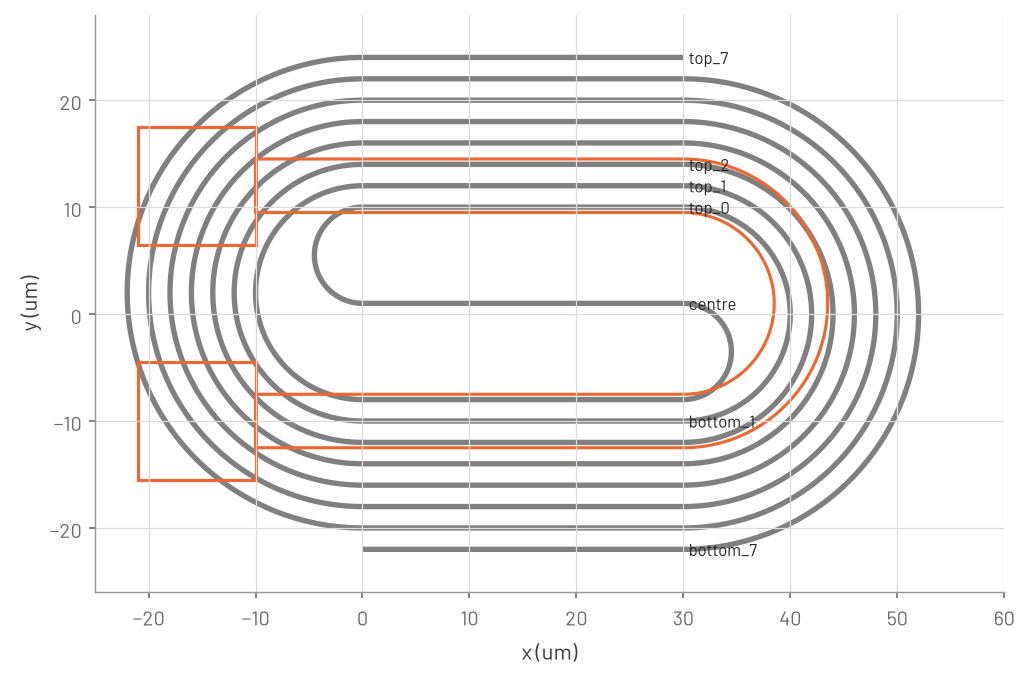

In [2]:
um = 1e-6
geometry = settings["geometry"]
names = [str(n) for n in out["pass_names"]]
pass_y = dict(zip(names, out["pass_y"], strict=True))

fig, ax = plt.subplots(figsize=(8, 5))
ax.add_patch(Polygon(out["core_polygon"], color="gray", lw=0))
ax.add_patch(Polygon(out["heater_polygon"], fill=False, color="C1", lw=1.5))
for pad in out["pad_polygons"]:
    ax.add_patch(Polygon(pad, fill=False, color="C1", lw=1.5))
for name in ("top_0", "top_1", "top_2", "top_7", "centre", "bottom_1", "bottom_7"):
    ax.annotate(name, (30.5, pass_y[name]), va="center", fontsize=8)
ax.set_xlim(-25, 60)
ax.set_ylim(-26, 28)
ax.set_aspect("equal")
ax.set_xlabel("x (um)")
ax.set_ylabel("y (um)");

The stack and the materials, as the run used them. The substrate is bulk Si,
148 W/m/K; the 0.22 µm film conducts heat less well, 90 W/m/K. The oxide is
1.38 W/m/K, and TiN 28 W/m/K with an electrical conductivity of 2.3 × 10⁶ S/m. The
thermo-optic coefficients are 1.86 × 10⁻⁴ /K in Si and 1 × 10⁻⁵ /K in the oxide.
These are the values of gsim's validation cases. The underside of the substrate,
13 µm below the core, is held at 293.15 K; every other outer face is insulated,
15 µm from the device.

```{literalinclude} ../../tools/heater3d_run.py
:pyobject: materials
```

```{literalinclude} ../../tools/heater3d_run.py
:pyobject: model
```

The mesh is graded tetrahedra from gmsh: 0.2 µm at the heater's surfaces, growing
to 4 µm over 8 µm, and 0.3 µm at the core's, growing to 4 µm over 4 µm. The heater
is one element thick. The cores are meshed as silicon, so they carry heat across
the oxide better than the oxide they replace. The temperature is solved at order 2.

In [3]:
for name in ("main", "medium", "fine"):
    m = next(m for m in settings["meshes"].values() if m["stage"] == name)
    print(
        f"{name}: heater {m['heater_um']} um, core {m['core_um']} um: "
        f"{m['tets']:,} tetrahedra, {m['dof']:,} temperature DOF at order "
        f"{settings['order']}, {m['dc_dof']:,} in the conductors"
    )

main: heater 0.2 um, core 0.3 um: 390,683 tetrahedra, 544,599 temperature DOF at order 2, 105,159 in the conductors
medium: heater 0.15 um, core 0.2 um: 606,433 tetrahedra, 839,973 temperature DOF at order 2, 147,331 in the conductors
fine: heater 0.1 um, core 0.15 um: 876,292 tetrahedra, 1,208,286 temperature DOF at order 2, 236,008 in the conductors


`main` is the mesh every result below comes from; `medium` and `fine` are the
mesh ladder of "Check your results".

## The current and the heat

`gfem.DCConduction` solves for the potential in the heater and pads with one pad's
top face at 1 V and the other's at 0 V, and gives the resistance.
`gfem.joule_heating` turns that solve into the heat source for any drive, here
1 W; `gfem.SteadyThermal` solves for the temperature. The problem is linear, so
every temperature below is a rise per watt, and every power scales it.
Temperatures are absolute, in kelvin; a rise is the temperature above the one
the sink sets with the heater off.

```{literalinclude} ../../tools/heater3d_run.py
:pyobject: device
```

In [4]:
resistance = float(out["main_resistance"])
power = float(out["main_power"])
current = 1e3 / np.sqrt(resistance)  # mA at 1 W
print(f"R = {resistance:.2f} ohm; at 1 W the current is {current:.1f} mA")
print(f"heat into the solve: {power:.6f} W")
print(
    f"mean rise per watt: heater {float(out['main_heater_rise']):.0f} K/W, "
    f"cores {float(out['main_core_rise']):.0f} K/W"
)

R = 99.16 ohm; at 1 W the current is 100.4 mA
heat into the solve: 1.000000 W
mean rise per watt: heater 2928 K/W, cores 695 K/W


The temperature rise per watt at the cores' mid-height (left) and across the
straights at $x = 15$ µm (right). The heater's U shows through the oxide as a broad
warm footprint: the cores under it rise by up to 1718 K per watt,
the heater itself by up to 3351 K/W. The cross-section shows the steep
drop across the 3 µm buried oxide, and the substrate below it almost at the sink's
temperature: silicon conducts heat a hundred times better than oxide.

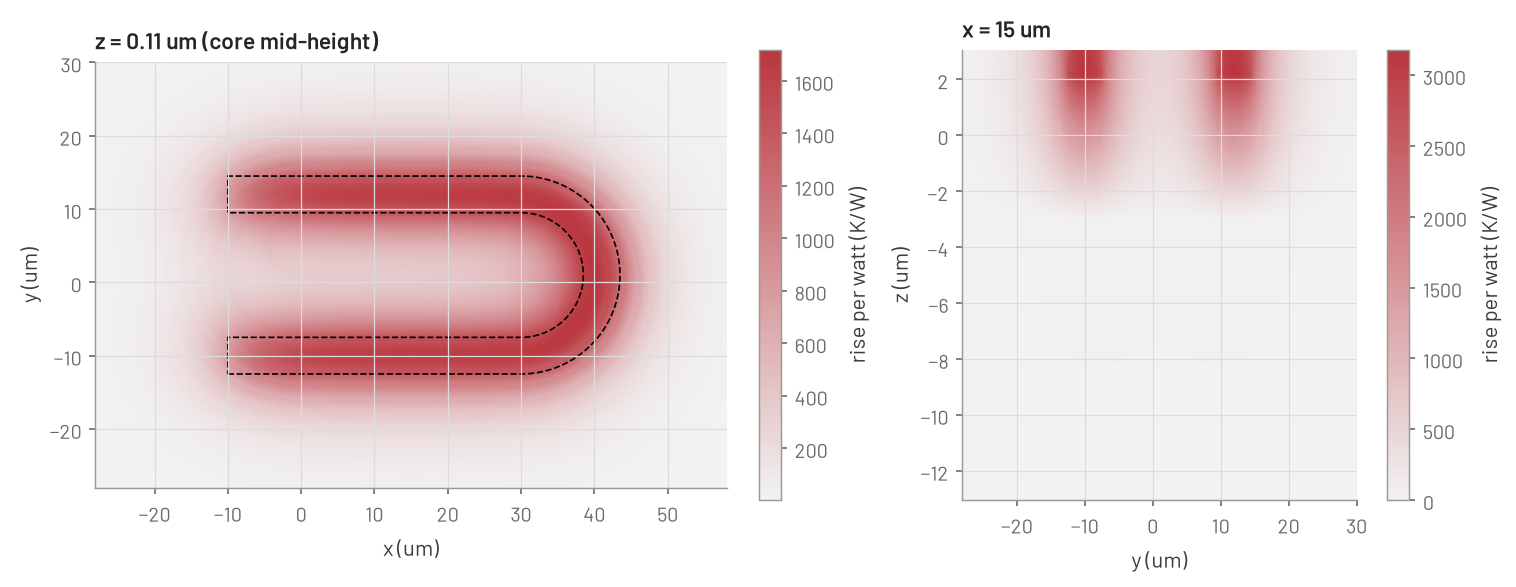

In [5]:
maps = settings["maps"]
fig, (top, cut) = plt.subplots(
    1, 2, figsize=(10, 3.8), width_ratios=[1.6, 1], layout="constrained"
)
x, y = out["map_x"], out["map_y"]
image = top.pcolormesh(x, y, out["map_core"], cmap="gfem_sensitivity", shading="auto")
top.add_patch(Polygon(out["heater_polygon"], fill=False, color="k", lw=0.8, ls="--"))
top.set_aspect("equal")
top.set_xlabel("x (um)")
top.set_ylabel("y (um)")
top.set_title(f"z = {maps['core_z_um']:g} um (core mid-height)")
fig.colorbar(image, ax=top, label="rise per watt (K/W)")
image = cut.pcolormesh(
    out["cut_y"], out["cut_z"], out["map_cut"], cmap="gfem_sensitivity", shading="auto"
)
cut.set_xlabel("y (um)")
cut.set_ylabel("z (um)")
cut.set_title(f"x = {maps['cut_x_um']:g} um")
fig.colorbar(image, ax=cut, label="rise per watt (K/W)");

## The phase along the route

The phase a temperature rise puts on the guided light comes from the mode of the
guide's cross-section. An **optical window**, the core in oxide 3.5 µm wide and
2.22 µm tall, is solved once for its fundamental TE-like mode at 1.55 µm. Its
first-order thermo-optic weights are then swept along the route: at stations
every 0.5 µm the window is placed across the guide, the 3D rise is read over it,
and the phase per length is integrated along the arc length. The bends use the
straight guide's mode; in these 220 nm silicon guides a bend moves the weights by
about 10⁻³ ({py:func}`gfem.route_phase`). The route is the
centreline at the core's underside, from the same generator as the meshed core.

```{literalinclude} ../../tools/heater3d_run.py
:pyobject: phase_route
```

$P_\pi$ follows from linearity: $P_\pi = \pi P / \varphi$, with $\varphi$ the route's phase at power $P$.

window mode: n_eff = 2.447252
route: 1241.99 um, phase 702.29 rad/W
P_pi = 4.473 mW, at 6.72 mA


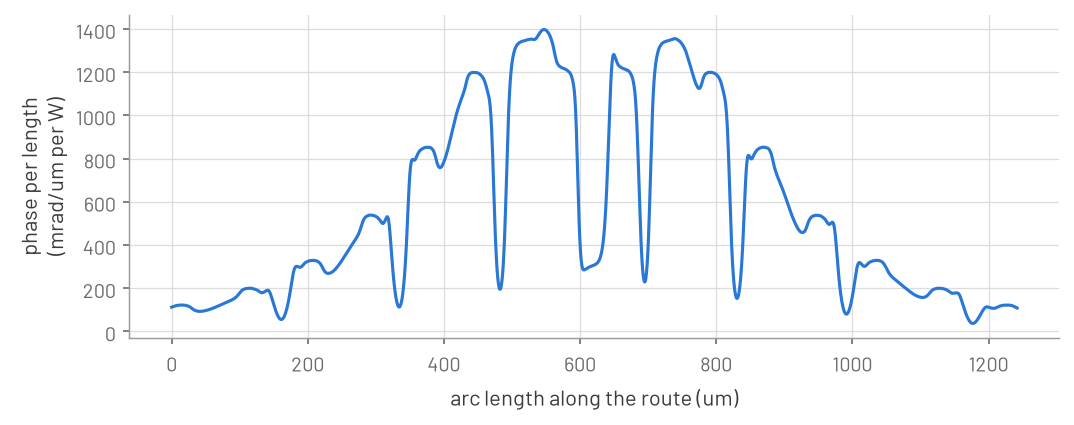

In [6]:
route_phase = float(out["main_route_phase"])
p_pi = np.pi * power / route_phase
print(f"window mode: n_eff = {float(out['n_eff']):.6f}")
print(f"route: {float(out['route_length']) / um:.2f} um, phase {route_phase:.2f} rad/W")
print(f"P_pi = {1e3 * p_pi:.3f} mW, at {1e3 * np.sqrt(p_pi / resistance):.2f} mA")
s = out["spiral_arc_length"] / um
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(s, out["spiral_phase_per_length"] * um * 1e3)
ax.set_xlabel("arc length along the route (um)")
ax.set_ylabel("phase per length\n(mrad/um per W)");

The phase per length along the route: one peak for each time the route passes
under the heater, the straights and the heater's semicircle, which crosses the
spiral's right-hand bends. The 17 straights from $x = 0$ to 30 µm hold
50 % of the phase; the rest is picked up in the bends.

## The passes and thermal crosstalk

Each straight of the spiral is a pass. Their phases come from the same
`route_phase` call, one route per pass from $x = 0$ to 30 µm. The passes centred
under the heater (`top_1`, `bottom_1`) take the most; their neighbours under the
heater's edges a little less; and the passes beside the heater, which only the
heat spreading through the oxide reaches, less again. **Thermal crosstalk** is
each pass's phase over the centre pass's.

 bottom_7: y = -22.0 um,   3.53 rad/W, crosstalk 0.088
 bottom_6: y = -20.0 um,   5.80 rad/W, crosstalk 0.145
 bottom_5: y = -18.0 um,   9.60 rad/W, crosstalk 0.240
 bottom_4: y = -16.0 um,  15.78 rad/W, crosstalk 0.394
 bottom_3: y = -14.0 um,  25.14 rad/W, crosstalk 0.628
 bottom_2: y = -12.0 um,  35.51 rad/W, crosstalk 0.887
 bottom_1: y = -10.0 um,  40.02 rad/W, crosstalk 1.000
 bottom_0: y =  -8.0 um,  36.38 rad/W, crosstalk 0.909
   centre: y =  +1.0 um,   9.73 rad/W, crosstalk 0.243
    top_0: y = +10.0 um,  36.38 rad/W, crosstalk 0.909
    top_1: y = +12.0 um,  40.02 rad/W, crosstalk 1.000
    top_2: y = +14.0 um,  35.50 rad/W, crosstalk 0.887
    top_3: y = +16.0 um,  25.14 rad/W, crosstalk 0.628
    top_4: y = +18.0 um,  15.79 rad/W, crosstalk 0.394
    top_5: y = +20.0 um,   9.60 rad/W, crosstalk 0.240
    top_6: y = +22.0 um,   5.80 rad/W, crosstalk 0.145
    top_7: y = +24.0 um,   3.53 rad/W, crosstalk 0.088


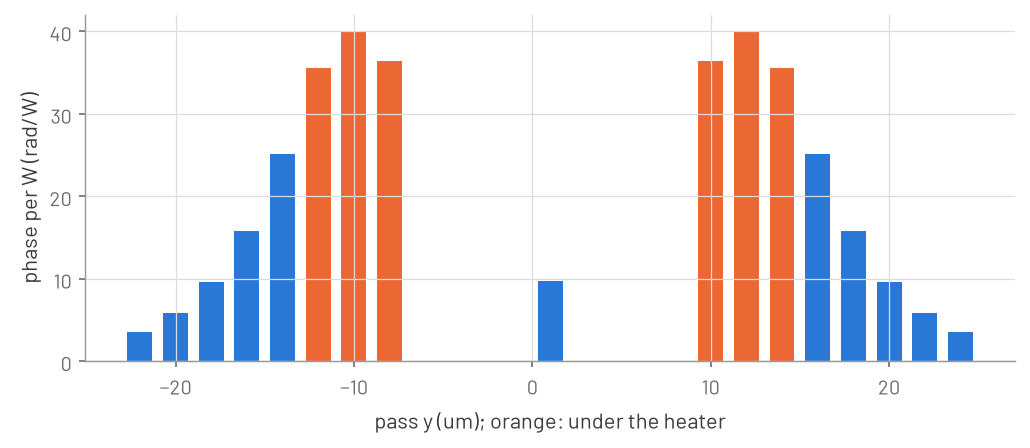

In [7]:
phases = dict(zip(names, out["main_pass_phase"], strict=True))
order = sorted(names, key=lambda n: pass_y[n])
centre_phase = phases["top_1"]
fig, ax = plt.subplots(figsize=(8, 3))
heater_y = geometry["heater_straights_y_um"]
colours = [
    "C1" if any(abs(pass_y[n] - h) < 2.5 for h in heater_y) else "C0" for n in order
]
ax.bar([pass_y[n] for n in order], [phases[n] for n in order], width=1.4, color=colours)
ax.set_xlabel("pass y (um); orange: under the heater")
ax.set_ylabel("phase per W (rad/W)")
for n in order:
    print(
        f"{n:>9}: y = {pass_y[n]:+5.1f} um, {phases[n]:6.2f} rad/W, "
        f"crosstalk {phases[n] / centre_phase:.3f}"
    )

The two centre passes take 40 rad/W each; the neighbours under the
heater's edges 0.89 to 0.91 of that. The
first passes outside the heater (`top_3`, `bottom_3`) still take
0.63, and the outermost 0.088: the oxide
spreads the heat over several passes on each side.

## The step response

`gfem.TransientThermal` switches the heater on at $t = 0$ at $P_\pi$, and off at
100 µs, in 400 TR-BDF2
steps. The route's phase is a trace of the solve (`RoutePhase.trace`), recorded
at every step with the same weights as the steady phase. It rises to within
0.2 % of $\pi$ by the switch-off and falls back to zero.

```{literalinclude} ../../tools/heater3d_run.py
:pyobject: step_response
```

switched on: time constant 17.03 us, 10-90 % rise time 34.31 us
switched off: time constant 17.03 us, 10-90 % rise time 34.30 us
phase at the switch-off: 3.1349 rad


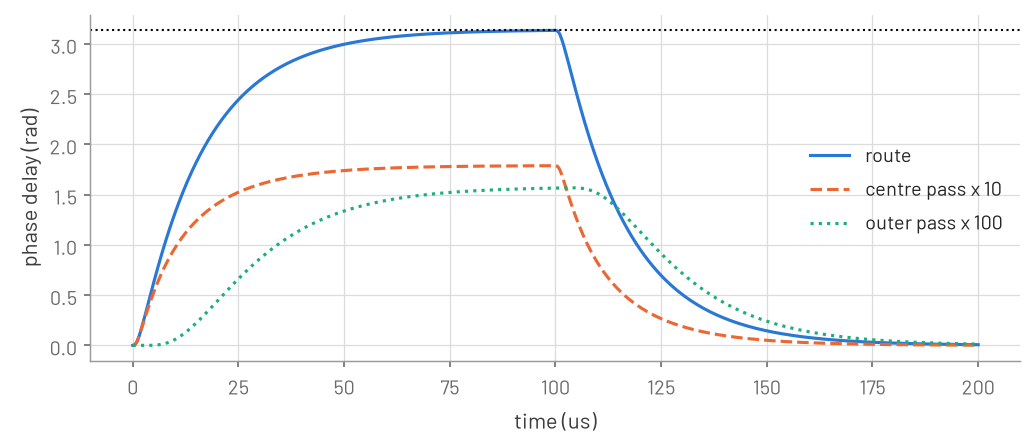

In [8]:
t = out["time"] / um  # us
ON = settings["step_response"]["on_s"] / um  # the switch-off, us
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t, out["trace_spiral"], label="route")
ax.plot(t, out["trace_centre_pass"] * 10, label="centre pass x 10")
ax.plot(t, out["trace_outer_pass"] * 100, label="outer pass x 100")
ax.axhline(np.pi, color="k", ls=":", lw=1)
ax.set_xlabel("time (us)")
ax.set_ylabel("phase delay (rad)")
ax.legend()
for edge in ("on", "off"):
    print(
        f"switched {edge}: time constant {out[f'time_constant_{edge}'] / um:.2f} us, "
        f"10-90 % rise time {out[f'rise_time_{edge}'] / um:.2f} us"
    )
print(f"phase at the switch-off: {out['trace_spiral'][t <= ON + 1e-6][-1]:.4f} rad")

The phase is a delay, positive here because silicon's $dn/dT$ is: a transmission's
argument moves by minus it. Heating and cooling are mirror images, as they must be
in a linear problem: the time constants on and off agree. The phase reaches
63 % of its swing in 17 µs and 90 % in 37.5 µs; the last few percent come
slower. The step is held for 100 µs, long
enough for the trace to settle: gfem warns when a trace is measured before it has.

The heater and the temperature on the cores' mid-plane, in 3D:

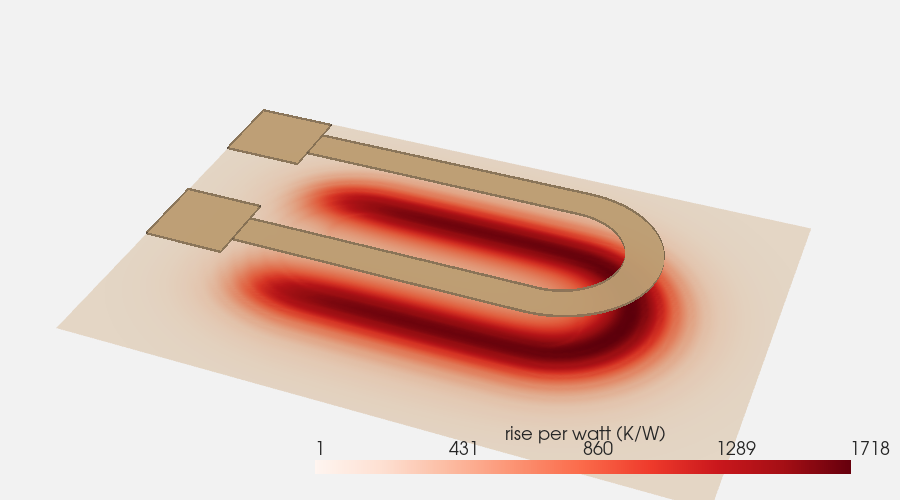

In [9]:
import pyvista as pv

pv.set_jupyter_backend("static")
every = 2
X, Y = np.meshgrid(x[::every], y[::every], indexing="ij")
plane = pv.StructuredGrid(X, Y, np.full_like(X, maps["core_z_um"]))
plane.point_data["rise (K/W)"] = out["map_core"][::every, ::every].T.ravel(order="F")
outline = np.c_[out["heater_polygon"], np.full(len(out["heater_polygon"]), 2.2)]
heater = pv.PolyData(outline, faces=[len(outline), *range(len(outline))])
heater = heater.triangulate().extrude((0, 0, 0.1), capping=True)
view = pv.Plotter(window_size=(900, 500))
view.add_mesh(
    plane,
    scalars="rise (K/W)",
    cmap="Reds",
    scalar_bar_args={"title": "rise per watt (K/W)", "fmt": "%.0f"},
)
view.add_mesh(heater, color="tan", opacity=0.8)
for pad in out["pad_polygons"]:
    x0, y0 = pad.min(0)
    x1, y1 = pad.max(0)
    view.add_mesh(pv.Box((x0, x1, y0, y1, 2.2, 2.3)), color="tan", opacity=0.8)
view.set_scale(zscale=4)
view.view_vector((0.4, -1, 0.8), viewup=(0, 0, 1))
view.camera.zoom(1.6)
view.show()

## Check your results

Five checks, each against something the solve does not use.

- **The resistance against the sheet count.** A strip of TiN 0.1 µm thick has a
  sheet resistance $1/(\sigma t) = 4.348$ Ω. The heater is two straights of 40 µm by
  5 µm, 8 squares each, and a semicircular strip between radii 8.5 and
  13.5 µm, $\pi / \ln(r_\mathrm{out} / r_\mathrm{in}) = 6.791$ squares:
  22.791 squares, 99.09 Ω. The pads, which the current enters
  through their whole top face, add almost nothing.
- **Power balance.** All the heat leaves through the substrate's underside: every
  other face is insulated. The heat through the sink is read from the discrete
  heat balance (`gfem.heat_flow`) and matches the Joule power.
- **The centre pass against a 2D section.** A cross-section of the same stack at
  $x = 15$ µm, with every pass's core and the heater's two straights at the power per
  length they carry in 3D ($I^2/(\sigma t w)$ each), gives the centre pass's phase per
  length through a window placed on it (`gfem.thermo_optic_shift`). The 3D pass is
  30 µm long, with heat leaving along it too, so its phase per length at $x = 15$ µm
  is expected a little below the section's.
- **The mesh ladder.** The same steady solve on two finer meshes.
- **A published sanity band.** A densely folded silicon spiral under a TiN heater
  is reported at about 3 mW for $\pi$ (Qiu et al., 2020). That device and its stack
  differ, so this is a scale, not a target.

In [10]:
rs = 1 / (2.3e6 * geometry["heater_thickness"] * um)
top_y, bottom_y = geometry["heater_straights_y_um"]
half = geometry["heater_width"] / 2
r_in, r_out = (top_y - bottom_y) / 2 - half, (top_y - bottom_y) / 2 + half
squares = 2 * (geometry["straight"] - geometry["heater_start"]) / geometry[
    "heater_width"
] + np.pi / np.log(r_out / r_in)
print(
    f"sheet count: {squares:.3f} squares x {rs:.3f} ohm = {squares * rs:.2f} ohm; "
    f"solved {resistance:.2f} ohm ({resistance / (squares * rs) - 1:+.2e})"
)
sink_power = float(out["sink_power"])
print(f"heat through the sink {sink_power:.9f} W for {power:.9f} W of Joule heat")
s3 = out["centre_pass_arc_length"]
mid = geometry["straight"] / 2 * um
station = float(np.interp(mid, s3, out["centre_pass_phase_per_length"]))
section = float(out["section_phase_per_length"])
print(
    f"centre pass at x = 15 um: 3D {station:.4g} rad/m per W, 2D section "
    f"{section:.4g} rad/m at {float(out['section_power_per_length']):.1f} W/m "
    f"per straight ({station / section - 1:+.2%})"
)
ladder = {}
for name in ("main", "medium", "fine"):
    m = next(m for m in settings["meshes"].values() if m["stage"] == name)
    p = np.pi * float(out[f"{name}_power"]) / float(out[f"{name}_route_phase"])
    ladder[name] = p
    r = float(out[f"{name}_resistance"])
    centre = dict(zip(names, out[f"{name}_pass_phase"], strict=True))["top_1"]
    print(
        f"{name:>6}: {m['dof']:>9,} DOF, R = {r:.3f} ohm, P_pi = {1e3 * p:.4f} mW, "
        f"centre pass {centre:.3f} rad/W"
    )

sheet count: 22.791 squares x 4.348 ohm = 99.09 ohm; solved 99.16 ohm (+7.40e-04)
heat through the sink 1.000000000 W for 1.000000000 W of Joule heat
centre pass at x = 15 um: 3D 1.343e+06 rad/m per W, 2D section 1.353e+06 rad/m at 8769.0 W/m per straight (-0.78%)
  main:   544,599 DOF, R = 99.164 ohm, P_pi = 4.4734 mW, centre pass 40.022 rad/W
medium:   839,973 DOF, R = 99.168 ohm, P_pi = 4.4716 mW, centre pass 40.071 rad/W
  fine: 1,208,286 DOF, R = 99.172 ohm, P_pi = 4.4702 mW, centre pass 40.083 rad/W


The sheet count gives 99.09 Ω against the solved 99.16 Ω. The
sink takes the Joule power to 2e-14. The 3D centre
pass at mid-straight is -0.8 % from the 2D section, which
has no heat flowing along the guide. Across the ladder,
0.54 M to 1.21 M DOF,
$P_\pi$ moves by at most 0.07 %. The 4.47 mW sits beside the
published ~3 mW for a denser spiral.

## Cost

The run's machine, and what each stage took. These are observations of that
machine, not benchmarks.

In [11]:
stages = provenance["stages"]
env = stages["main"]["environment"]
print(
    f"run record: {record['profile']} profile, gfem {env['versions']['gfem']} at "
    f"commit {provenance['commit'][:12]}"
)
print(
    f"machine: {env['cpu_model']}, {env['threads']} logical CPUs allocated, "
    f"{env['memory_limit_bytes'] / 2**30:.0f} GiB, {env['os']}; NGSolve "
    f"{env['versions']['ngsolve']}, MKL {env['versions']['mkl']} (PARDISO "
    f"{'available' if env['pardiso_available'] else 'absent'})"
)
for name, seen in observed.items():
    steps = ", ".join(f"{k[:-2]} {v:.1f} s" for k, v in seen["steps_s"].items())
    print(
        f"{name}: {seen['wall_s'] / 60:.1f} min, peak memory "
        f"{seen['peak_rss_bytes'] / 2**30:.1f} GiB ({steps})"
    )

run record: full profile, gfem 0.1.0 at commit 91af3899975b
machine: Intel(R) Xeon(R) Platinum 8480+, 32 logical CPUs allocated, 252 GiB, Red Hat Enterprise Linux 9.6 (Plow); NGSolve 6.2.2608, MKL 2026.2.0 (PARDISO available)
main: 8.4 min, peak memory 4.5 GiB (mesh 40.9 s, read 12.2 s, dc 9.4 s, steady 7.1 s, route 332.7 s, maps 2.1 s, section 6.7 s, transient 82.3 s)
medium: 8.8 min, peak memory 4.8 GiB (mesh 57.5 s, read 18.4 s, dc 2.3 s, steady 10.9 s, route 437.7 s)
fine: 11.0 min, peak memory 6.6 GiB (mesh 68.2 s, read 26.6 s, dc 4.4 s, steady 16.1 s, route 543.9 s)


## Limits

- **Constant, linear material data.** Conductivities and $dn/dT$ do not depend on
  temperature, and the TiN's resistance does not rise as it heats; at
  15 K of heater rise at $P_\pi$ that is an approximation.
- **A first-order phase with the straight guide's mode.** The phase is first
  order in the rise and uses the straight guide's mode in the bends too; both are
  about 10⁻⁴ to 10⁻³ effects here. The
  phase is the thermo-optic delay alone: no change of path length from thermal
  expansion.
- **Material values from one source.** The thin-film conductivities of TiN and
  silicon depend on the process; the 90 W/m/K of the 220 nm film and the
  2.3 × 10⁶ S/m of TiN move $R$, $P_\pi$ and the time constant directly.
- **An idealised chip.** No metal wiring, vias or back-end layers, no air above
  the cladding (an insulated top), and a heat sink 13 µm below the core instead
  of a full wafer and package.

## How this was run

- The run is
  [`tools/heater3d_run.py`](https://github.com/benvial/gfem/blob/main/tools/heater3d_run.py),
  with the geometry from
  [`tools/heater_geometry.py`](https://github.com/benvial/gfem/blob/main/tools/heater_geometry.py).
  From a clone of the repository, `just heater3d-data` reruns it (gmsh 4.15.2 builds
  the meshes) and rewrites the saved results.
- The numbers are those of the gfem version that ran (printed under "Cost"). A later
  gfem does not update them.

## Next

- {doc}`../recipes/thermo-optic-phase`: the phase of a temperature rise on a
  cross-section and along a route.
- {doc}`../recipes/thermal-step-response`: transient solves, traces, rise times
  and time constants.
- {doc}`../recipes/heater-temperature`: materials, boundaries and drives of a
  heater, in 2D and 3D.
- [The heater tutorial](heater.ipynb): one heater over a waveguide as a 2D
  cross-section, run in place, with its step response and published bands.
- [The 3D bend tutorial](bend3d.ipynb): another page published from a run record.

In [12]:
# The page's checks, on the record it read.
route_length = float(out["route_length"]) / um
np.testing.assert_allclose(route_length, geometry["route_length_um"], rtol=1e-5)
np.testing.assert_allclose(sink_power, power, rtol=1e-6)
np.testing.assert_allclose(resistance, squares * rs, rtol=1e-2)
np.testing.assert_allclose(station, section, rtol=0.1)
ladder_spread = max(abs(p / ladder["fine"] - 1) for p in ladder.values())
np.testing.assert_array_less(ladder_spread, 5e-3)
np.testing.assert_allclose(out["trace_spiral"][t <= ON + 1e-6][-1], np.pi, rtol=1e-2)
np.testing.assert_allclose(out["trace_spiral"][-1], 0.0, atol=3e-2)
print(f"checks passed; ladder spread {ladder_spread:.1e}")

checks passed; ladder spread 7.2e-04
